<a href="https://colab.research.google.com/github/Just-polite/4IK25CS187_DAV_LAB/blob/main/4IK25CS187_EXP_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lab 7- Simple and multiple linear regression: Building Models,checking assumptions ,evaluating r2 and RMSE

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn .linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error

Load and clean data

In [2]:
df=pd.read_csv("/content/Titanic-Dataset.csv")
df=df[["Fare","Pclass","Age","SibSp","Parch"]]
df["Age"]=df["Age"].fillna(df["Age"].median()) #fill missing values
df=df[df["Fare"]>0]

Simple Linear Regression

In [3]:
x_simple=df[["Pclass"]]
y=df["Fare"]
x_tr,x_te,y_tr,y_te=train_test_split(x_simple,y,test_size=0.2,random_state=42)
model_simple=LinearRegression().fit(x_tr,y_tr)
pred_simple=model_simple.predict(x_te)
print("SIMPLE REGRESSION -- INTERCEPT:",round(model_simple.intercept_,2))
print("SIMPLE REGRESSION --SLOPE: ",round(model_simple.coef_[0],2))
print("SIMPLE REGRESSION --R2: ",round(r2_score(y_te,pred_simple),3))
print("SIMPLE REGRESSION --RMSE: ",round(np.sqrt(mean_squared_error(y_te,pred_simple)),2))

SIMPLE REGRESSION -- INTERCEPT: 112.38
SIMPLE REGRESSION --SLOPE:  -34.23
SIMPLE REGRESSION --R2:  0.371
SIMPLE REGRESSION --RMSE:  35.68


Multiple Linear Regression

In [4]:
x_multi=df[["Pclass","Age","SibSp","Parch"]]
x_tr2,x_te2,y_tr2,y_te2=train_test_split(x_multi,y,test_size=0.2,random_state=42)
model_multi=LinearRegression().fit(x_tr2,y_tr2)
pred_multi=model_multi.predict(x_te2)
print("MULTIPLE REGRESSION --Intercept:",round(model_multi.intercept_,2))
for name,coef in zip(x_multi.columns,model_multi.coef_):
  print("MULTIPLE REGRESSION --COEFFICIENT OF ",name,":",round(coef,2))
print("MULTIPLE REGRESSION --R2:",round(r2_score(y_te2,pred_multi),3))
print("MULTIPLE REGRESSION --RMSE:",round(np.sqrt(mean_squared_error(y_te2,pred_multi)),2))

MULTIPLE REGRESSION --Intercept: 112.3
MULTIPLE REGRESSION --COEFFICIENT OF  Pclass : -35.72
MULTIPLE REGRESSION --COEFFICIENT OF  Age : -0.12
MULTIPLE REGRESSION --COEFFICIENT OF  SibSp : 5.38
MULTIPLE REGRESSION --COEFFICIENT OF  Parch : 10.09
MULTIPLE REGRESSION --R2: 0.462
MULTIPLE REGRESSION --RMSE: 33.0


plot:Simple regression line

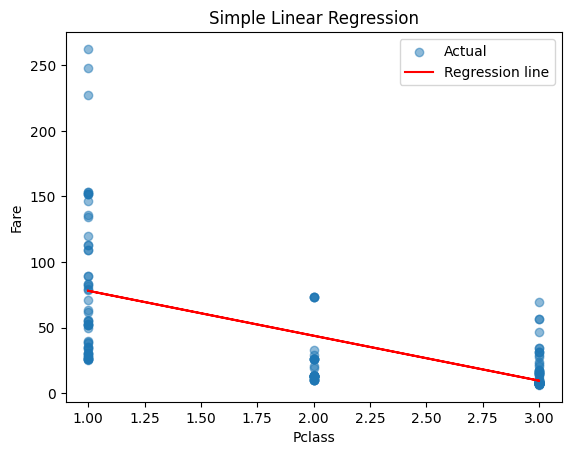

In [5]:
plt.scatter(x_te,y_te,alpha=0.5,label="Actual")
plt.plot(x_te,pred_simple,color="red",label="Regression line")
plt.xlabel("Pclass")
plt.ylabel("Fare")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

checking assumptions(Multiple Regression)

1.linearly and equal variance

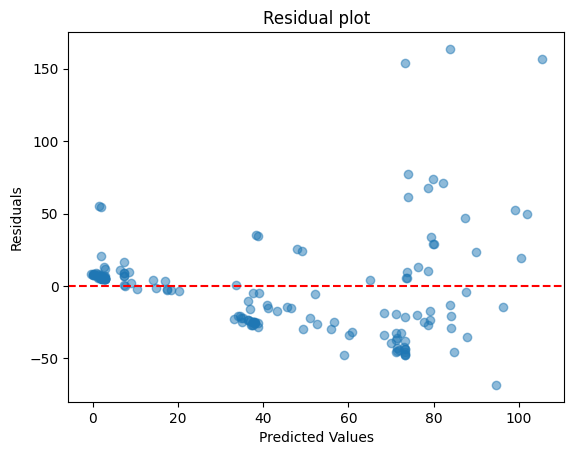

In [6]:
residuals=y_te2-pred_multi
plt.scatter(pred_multi,residuals,alpha=0.5)
plt.axhline(y=0,color="red",linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual plot")
plt.show()

2.Normality :residuals should look roughly bell shaped

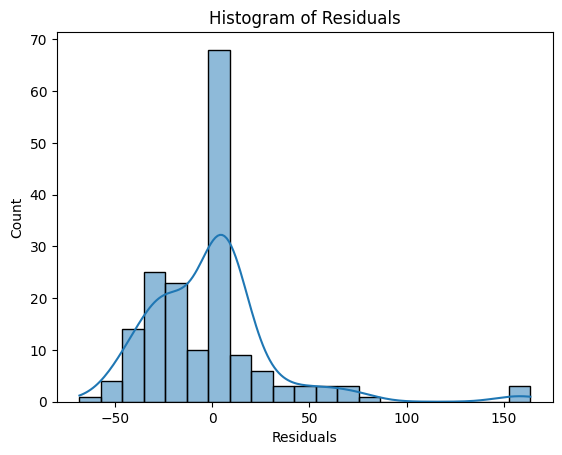

In [7]:
sns.histplot(residuals,kde=True)
plt.xlabel("Residuals")

plt.title("Histogram of Residuals")
plt.show()


Multicollinearity :input features should not be strongly correlated

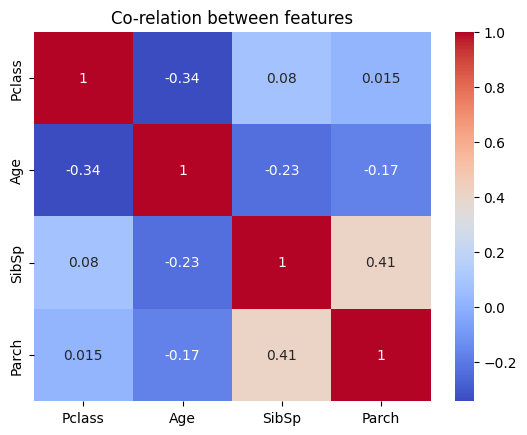

In [8]:
sns.heatmap(x_multi.corr(),annot=True,cmap='coolwarm')
plt.title("Co-relation between features")
plt.show()